# Forecasting French power in 2025

*Hourly demand, solar, wind and electricity price, from weather, fuel prices and the state of the power plants.*

**The question.** Kpler gives me hourly weather, fuel prices and plant data for 2020 to 2025, plus the real demand, solar, wind and price up to the end of 2024. I have to forecast those four series for every hour of 2025.

**The short version.** Demand and wind are forecast closely, solar well in daytime, and the price much less well: it is right in winter but too high in spring and summer 2024, because the market behaved in ways the data cannot explain. Two ideas did most of the work: forecasting solar and wind as *shares* of capacity, and separating what fuel prices explain in the price from what the supply and demand of the hour explain.


| | Section | The question it answers |
|---|---|---|
| 0 | Setup and vocabulary | What are the words and tools? |
| 1 | The data | What do we have, and what could trip a model up? |
| 2 | How to judge a forecast | How do we know it works on a year it has never seen? |
| 3 | The model at a glance | What does the model look like? |
| 4 | Four ideas that made the difference | What did we have to get right? |
| 5 | Does it work? | How good is it? |
| 6 | Opening the price model | How does it arrive at a price? |
| 7 | Where it still fails | What does it get wrong, and why? |
| 8 | The 2025 forecast | Does the forecast behave sensibly? |
| 9 | Next steps | What would we do with more time or more data? |

## 0. Setup

In [1]:
import inspect
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Code, display
from sklearn.linear_model import LinearRegression

from kpler_forecast import TARGETS
from kpler_forecast.evaluate import fct_evaluate__backtest, fct_evaluate__seasonal_naive
from kpler_forecast.features import fct_features__market, fct_features__weather
from kpler_forecast.models import (CALENDAR, FEATURES, FUELS, Forecaster, fct_models__base_features,
                                   fct_models__booster, fct_models__fuel_model)

ROOT = Path("..")
DATA = ROOT / "data"

*(skip on first read)* Styles and small helpers. Colors keep the same meaning all along: **grey** is what really happened, **blue** is the model, **orange** is a problem.

In [2]:
GREY, BLUE, ORANGE, MUTED = "#52514e", "#2a78d6", "#eb6834", "#b5b4ae"
INK, GRID = "#0b0b0b", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "axes.edgecolor": GREY,
    "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY, "text.color": INK,
    "lines.linewidth": 2, "legend.frameon": False,
})

ORDER = ["FR_load_actual", "FR_solar_actual", "FR_wind_actual", "FR_price_actual"]
NAMES = {"FR_load_actual": "Demand", "FR_solar_actual": "Solar", "FR_wind_actual": "Wind", "FR_price_actual": "Price"}
UNITS = {"FR_load_actual": "MW", "FR_solar_actual": "MW", "FR_wind_actual": "MW", "FR_price_actual": "€/MWh"}


def fct_notebook__fit_predict(X_train, y_train, X_valid, cols, objective="l2", weight=None):
    # one model with the package's booster, for the side experiments in this notebook
    ok = y_train.notna().to_numpy()
    model = fct_models__booster(objective)
    model.fit(X_train.loc[ok, cols], y_train[ok], sample_weight=None if weight is None else weight[ok])
    return pd.Series(model.predict(X_valid[cols]), index=X_valid.index)


def fct_notebook__mae(pred, col):
    return (pred - targets.loc[pred.index, col]).abs().mean()


def fct_notebook__level_error(truth, pred):
    # average error as a share of the average level, so that the four series fit on one scale
    return (pred - truth).abs().mean() / truth.abs().mean() * 100


def fct_notebook__week(ax, truth, pred, title):
    ax.plot(truth, color=GREY, lw=2.2, label="actual")
    ax.plot(pred, color=BLUE, lw=1.8, label="forecast")
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.tick_params(axis="x", labelsize=7)

## 1. The data

*What do we have, and what could trip a model up?*

Five files, all hourly and in UTC: the weather on 312 tiles covering France, fuel prices and the state of the power plants (the "network" file), and the four series to forecast.

In [3]:
raw = pd.read_parquet(DATA / "target_train.parquet")
display(raw.head(10))              # --> what we forecast

network = pd.read_parquet(DATA / "network_train.parquet")
network_25 = pd.read_parquet(DATA / "network_test.parquet")
display(network.head(10))        # --> fuel prices, installed capacity, plants available

weather = pd.read_parquet(DATA / "weather_train.parquet")
weather_25 = pd.read_parquet(DATA / "weather_test.parquet")
display(weather.iloc[:10, :6])       # --> one column per [zone, tile, weather variable] // WARNING : not all weather variable are present for all tiles

,FR_load_actual,FR_price_actual,FR_solar_actual,FR_wind_actual
start_date,,,,
2020-01-01 00:00:00+00:00,63191.75,38.599998,0.0,2810.0
2020-01-01 01:00:00+00:00,61903.75,36.549999,0.0,2655.0
2020-01-01 02:00:00+00:00,58716.00,32.320000,0.0,2736.0
2020-01-01 03:00:00+00:00,56448.25,30.850000,0.0,2631.0
2020-01-01 04:00:00+00:00,55891.00,30.139999,0.0,2533.0
2020-01-01 05:00:00+00:00,56021.25,30.170000,0.0,2341.0
2020-01-01 06:00:00+00:00,56287.00,30.000000,0.0,2185.0
2020-01-01 07:00:00+00:00,56243.25,30.650000,175.0,1917.0
2020-01-01 08:00:00+00:00,56557.25,30.650000,640.0,1694.0


,EEX_CARBON,EEX_COAL,EEX_GAS_PEG,FR_capacity_solar,FR_capacity_wind,FR_availability_coal,FR_availability_gas,FR_availability_hydro,FR_availability_nuclear
start_date,,,,,,,,,
2020-01-01 00:00:00+00:00,24.639999,47.178207,11.65,9438.000000,49734.000000,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 01:00:00+00:00,24.639999,47.178207,11.65,9438.089844,49734.210938,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 02:00:00+00:00,24.639999,47.178207,11.65,9438.179688,49734.453125,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 03:00:00+00:00,24.639999,47.178207,11.65,9438.259766,49734.664062,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 04:00:00+00:00,24.639999,47.178207,11.65,9438.349609,49734.867188,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 05:00:00+00:00,24.639999,47.178207,11.65,9438.440430,49735.078125,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 06:00:00+00:00,24.639999,47.178207,11.65,9438.530273,49735.320312,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 07:00:00+00:00,24.639999,47.178207,11.65,9438.620117,49735.531250,1757.0,12025.05957,13562.0,50557.941406
2020-01-01 08:00:00+00:00,24.639999,47.178207,11.65,9438.709961,49735.742188,1757.0,12025.05957,13562.0,50557.941406


zone                                                    FR            \
tile_id                   006d9e54d8b83baf86c443cba26fe066             
weather_var                                           ssrd       tcc   
start_date                                                             
2020-01-01 00:00:00+00:00                              NaN  0.888672   
2020-01-01 01:00:00+00:00                          0.00000  0.976074   
2020-01-01 02:00:00+00:00                          0.00000  0.990723   
2020-01-01 03:00:00+00:00                          0.00000  1.000000   
2020-01-01 04:00:00+00:00                          0.00000  0.939941   
2020-01-01 05:00:00+00:00                          0.00000  0.885254   
2020-01-01 06:00:00+00:00                          0.00000  0.958496   
2020-01-01 07:00:00+00:00                          0.00000  0.874512   
2020-01-01 08:00:00+00:00                       4999.89502  0.673340   
2020-01-01 09:00:00+00:00                     183777.93750  0.753418   

zone                                                                  \
tile_id                   00a5ba9b5c6956348da64608421b52f2             
weather_var                                           ssrd       tcc   
start_date                                                             
2020-01-01 00:00:00+00:00                              NaN  0.000000   
2020-01-01 01:00:00+00:00                              0.0  0.106567   
2020-01-01 02:00:00+00:00                              0.0  0.235718   
2020-01-01 03:00:00+00:00                              0.0  0.298096   
2020-01-01 04:00:00+00:00                              0.0  0.469971   
2020-01-01 05:00:00+00:00                              0.0  0.734375   
2020-01-01 06:00:00+00:00                              0.0  0.787109   
2020-01-01 07:00:00+00:00                              0.0  0.905273   
2020-01-01 08:00:00+00:00                              0.0  0.949219   
2020-01-01 09:00:00+00:00                          93056.0  0.963867   

zone                                                                  
tile_id                   01be41406272e75c7e5cbcf9e290139d            
weather_var                                          100ws      ssrd  
start_date                                                            
2020-01-01 00:00:00+00:00                         1.789586       NaN  
2020-01-01 01:00:00+00:00                         0.595327       0.0  
2020-01-01 02:00:00+00:00                         0.731508       0.0  
2020-01-01 03:00:00+00:00                         1.554017       0.0  
2020-01-01 04:00:00+00:00                         1.987131       0.0  
2020-01-01 05:00:00+00:00                         1.167321       0.0  
2020-01-01 06:00:00+00:00                         1.117584       0.0  
2020-01-01 07:00:00+00:00                         1.015413       0.0  
2020-01-01 08:00:00+00:00                         1.370861   44928.0  
2020-01-01 09:00:00+00:00                         1.777679  384640.0

Before any modelling, here are the 4 series over five years (monthly averages):

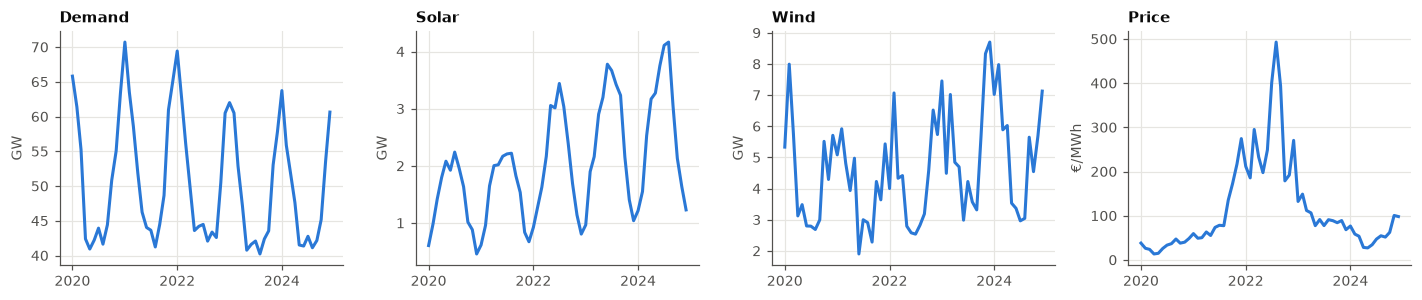

In [4]:
monthly = raw[raw.index.year < 2025].resample("MS").mean()

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, col in zip(axes, ORDER):
    scale = 1 if col == "FR_price_actual" else 1 / 1000
    ax.plot(monthly.index, monthly[col] * scale, color=BLUE)
    ax.set(title=NAMES[col], ylabel="€/MWh" if col == "FR_price_actual" else "GW")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout();

Three things stand out, and the rest of the notebook is built around them:

- **Solar keeps growing.** 2025 will have more panels than anything the model sees in training.
- **2022 is unlike other years.** The price explodes, and demand never quite comes back afterwards.
- **Prices are volatile.** A model that learns "the price" from 2022 is learning an exception.

### Cleaning

Mostly housekeeping:

| What we found | What we did |
|---|---|
| The training targets end with one hour of 2025 | dropped it, it belongs to the test year |
| A few hours are missing (demand, every spring at 1AM an hour skipped by clock change; more for solar and wind) | left empty, the models skip them when they learn |
| One wind value far above anything else, then straight back to normal | removed |
| Solar output above the installed capacity, in one hour | removed, it cannot be real |
| Irradiance comes in joules per m² per hour | converted to watts per m² (divide by 3600) |
| Each weather variable exists on only some of the 312 tiles | average over France, plus learned tile weights for solar and wind (section 4) |
| The wind capacity column implies a low average load factor, and we can't tell what it really measures | used as a growth trend only, not as a physical truth |

In [5]:
targets = raw[TARGETS].astype("float64")
targets = targets[targets.index.year < 2025] # the file ends with one hour of 2025
weather, network = weather.loc[targets.index], network.loc[targets.index]

targets.loc[targets.FR_solar_actual > network.FR_capacity_solar, "FR_solar_actual"] = np.nan # more than the whole fleet can produce
targets.loc[targets.FR_wind_actual / network.FR_capacity_wind > 0.5, "FR_wind_actual"] = np.nan  # above 50% of capacity: the isolated spike

X = fct_models__base_features(weather) # weather aggregates + calendar (Paris time)
year = targets.index.year
 #the split used in the examples below:
train = year < 2024
valid = year == 2024

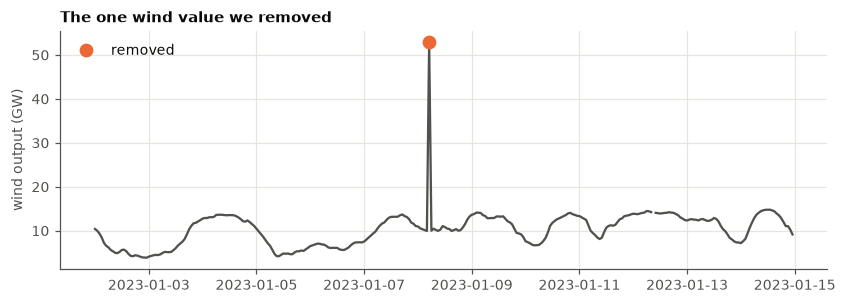

In [6]:
window = slice("2023-01-02", "2023-01-14")
#we look for the one wind value that is present in the raw data but missing in the targets, and remove it from the raw data (to avoid a mismatch)
raw_wind = raw.FR_wind_actual[window]
removed = raw_wind[targets.FR_wind_actual[window].isna() & raw_wind.notna()]

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(raw.FR_wind_actual[window] / 1000, color=GREY, lw=1.5)
ax.plot(removed.index, removed / 1000, "o", color=ORANGE, ms=8, label="removed")
ax.set(title="The one wind value we removed", ylabel="wind output (GW)")
ax.legend(loc="upper left");

> **Takeaway:** the data is mostly clean. The real traps are not typos: it's a fleet that keeps growing and 2022 that behaves quite differently from the rest.

## 2. How to judge our forecast

*How do I know the model works on a year it has never seen?*

I replay the past: **train on the years before, forecast the next year.**

- **2024** is the main exam, the closest year to 2025.
- **2023** is a harder test: the model has seen only a few months of the post-2022 world.
- The final model is trained on everything up to 2024.

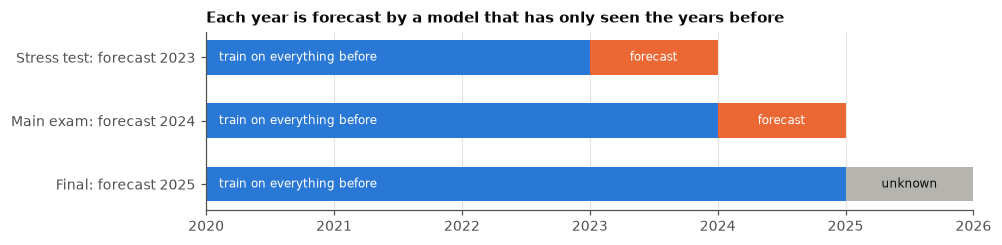

**What counts as good?** The simplest thing one could do: **repeat the same hour 52 weeks earlier** (same weekday, one year ago). Here it is on a week of 2024 demand:

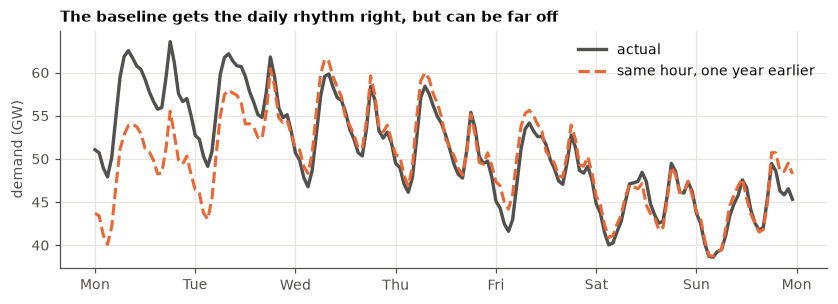

In [7]:
naive = fct_evaluate__seasonal_naive(targets, targets.index[valid])
week = slice("2024-03-11", "2024-03-17") #random slice

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(targets.FR_load_actual[week] / 1000, color=GREY, lw=2.2, label="actual")
ax.plot(naive.FR_load_actual[week] / 1000, color=ORANGE, ls="--", label="same hour, one year earlier")
ax.set(title="The baseline gets the daily rhythm right, but can be far off", ylabel="demand (GW)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))
ax.legend(loc="upper right");

The four series have different units, so I also give the average error as a share of the series' typical level: a 5% error on demand and a 5% error on the price then mean the same thing.

## 3. Model

*What does the model look like?*

Four models, one per series. The price model comes last, because the price depends on demand, solar and wind: it is fed the forecasts of the other three.

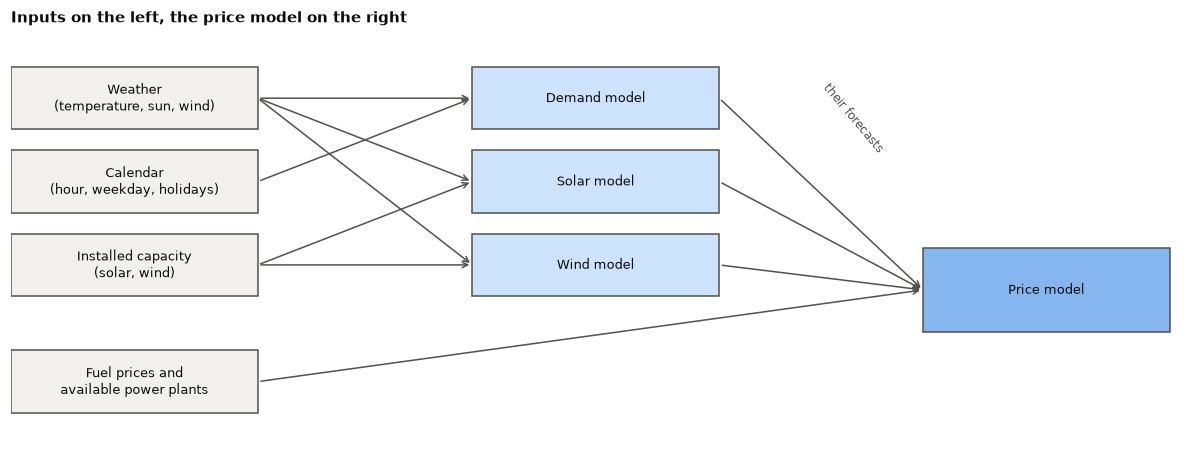

All four are gradient-boosted trees (XGBoost) with fixed settings. The work is in what they are fed and what they are asked to predict. Here is the training code, straight from kpler_forecast/models.py:

In [8]:
display(Code(inspect.getsource(Forecaster.fit), language="python"))

def fit(self, weather, network, targets):
        """Fit the forecaster on the given data."""
        X = fct_models__base_features(weather)
        
        # 1. Train models for physical targets (load, solar, wind)
        for target in ["FR_load_actual", "FR_solar_actual", "FR_wind_actual"]:
            y = targets[target]
            
            if target in CAPACITY:
                y = y / network[CAPACITY[target]]
                # Plants aren't spread evenly: a positive linear fit on the tiles finds where they are
                tiles = self._tiles(weather, target)
                ok = y.notna()
                
                self.tile_weights[target] = LinearRegression(positive=True).fit(tiles[ok], y[ok])
                X = X.assign(tiles=self.tile_weights[target].predict(tiles))
                
            self.models[target] = self._fit_one(X[FEATURES[target]], y)

        # 2. Train the electricity price model
        # - Trained on actual load/solar/wind, fed our forecasts at inference 
        #   (training on out-of-fold forecasts helped a little in one test, not adopted).
        # - Target is the spread over the fuel cost: fuel prices moved 10x in 2022 but the spread much less.
        # - L1 so the 2022 spikes don't drag the fit.
        self.fuel_model = fct_models__fuel_model(network, targets.FR_price_actual)
        
        market_features = fct_features__market(
            network, 
            targets.FR_load_actual, 
            targets.FR_solar_actual, 
            targets.FR_wind_actual
        )
        Xp = X.join(market_features)
        Xp["fuel_cost"] = self.fuel_model.predict(network[FUELS])
        
        spread = targets.FR_price_actual - Xp.fuel_cost
        self.models["FR_price_actual"] = self._fit_one(
            Xp[FEATURES["FR_price_actual"]], 
            spread, 
            objective="l1"
        )

        # 3. Capture run metadata
        now = datetime.now(timezone.utc)
        self.meta = {
            "version": now.strftime("%Y%m%d_%H%M"), 
            "trained_at": now.isoformat(timespec="seconds"),
            "train_start": str(targets.index.min()), 
            "train_end": str(targets.index.max()),
            "features": FEATURES,
            "params": XGB_PARAMS
        }
        
        return self

Three things to notice (each explained in section 4):

1. Solar and wind are forecast as a **share of installed capacity**, then multiplied back by the capacity.
2. For solar and wind, a small first model **learns which weather tiles matter**.
3. The price model forecasts **the gap to the level that fuel prices explain**, and that level is added back at the end.

Now I run the two validations once (about 15 seconds). Most charts below reuse them.

In [9]:
results = {y: fct_evaluate__backtest(weather, network, targets, valid_year=y) for y in [2023, 2024]}
p24, t24 = results[2024]["pred"], results[2024]["truth"]

> **Takeaway.** Four models in a chain, with the physics in the inputs rather than in the settings.

## 4. Four ideas that made the difference

*What did I have to get right?*

Each idea came from a specific failure. To measure what it is worth, I remove it, refit, and compare the errors. The recap is at the end of the section.

In [10]:
worth = {} # error without an idea, and with it, filled in below
PF = FEATURES["FR_price_actual"]

### 4.1 Solar: forecast a share of the capacity, not megawatts

The solar fleet keeps growing, and trees cannot predict above what they saw in training. So the model forecasts the *share of installed capacity* (0-100%), then multiplies by the capacity of the day. I trained the same model both ways on the years before 2024:

In [11]:
night = X.sun_elev[valid] <= -2 # sun below the horizon (-2°) : no output
cols = [c for c in FEATURES["FR_solar_actual"] if c != "tiles"]
share = targets.FR_solar_actual / network.FR_capacity_solar #share of the fleet's capacity actually produced

solar_mw = fct_notebook__fit_predict(X[train], targets.FR_solar_actual[train], X[valid], cols).mask(night, 0).clip(lower=0)
solar_pct = (fct_notebook__fit_predict(X[train], share[train], X[valid], cols) * network.FR_capacity_solar[valid]).mask(night, 0).clip(lower=0)

worth["Solar: forecast a share of capacity"] = (fct_notebook__mae(solar_mw, "FR_solar_actual"), fct_notebook__mae(solar_pct, "FR_solar_actual"))
worth["Solar: learn which tiles matter"] = (fct_notebook__mae(solar_pct, "FR_solar_actual"), fct_notebook__mae(p24.FR_solar_actual, "FR_solar_actual"))

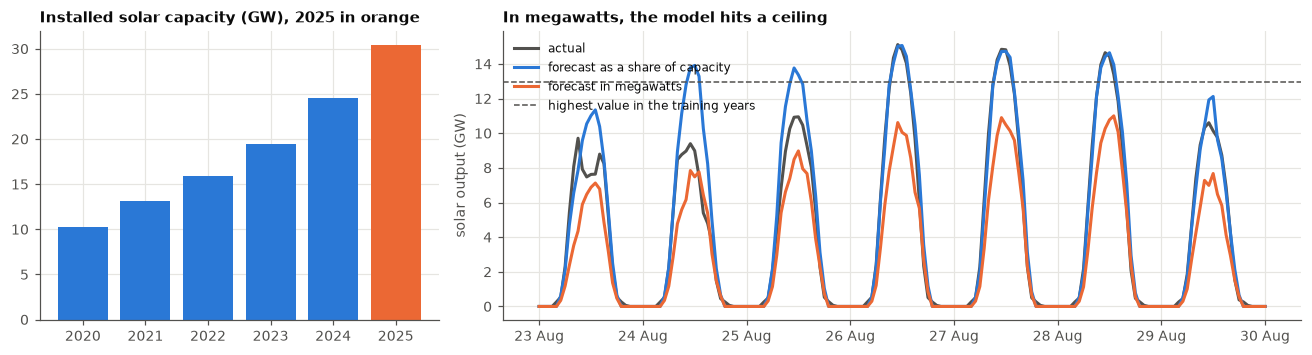

In [12]:
# Combine solar capacity and calculate yearly ending values in GW
capacity = pd.concat([network.FR_capacity_solar, network_25.FR_capacity_solar])
cap_end = capacity.groupby(capacity.index.year).last() / 1000
# Extract the peak solar generation day and define a surrounding 7-day window
peak_day = t24.FR_solar_actual.idxmax().normalize()
week = slice(peak_day - pd.Timedelta(days=3), peak_day + pd.Timedelta(days=4))
# Retrieve the previous historical peak from training targets in GW
previous_record = targets.FR_solar_actual[train].max() / 1000

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(cap_end.index, cap_end, color=[ORANGE if y == 2025 else BLUE for y in cap_end.index])
axes[0].set(title="Installed solar capacity (GW), 2025 in orange")

ax = axes[1]
ax.plot(t24.FR_solar_actual[week] / 1000, color=GREY, label="actual")
ax.plot(solar_pct[week] / 1000, color=BLUE, label="forecast as a share of capacity")
ax.plot(solar_mw[week] / 1000, color=ORANGE, label="forecast in megawatts")
ax.axhline(previous_record, color=GREY, ls="--", lw=1, label="highest value in the training years")
ax.set(title="In megawatts, the model hits a ceiling", ylabel="solar output (GW)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(fontsize=8)
fig.tight_layout();

The orange model hits a ceiling: the highest value it saw in training. Note also the weekend (24 and 25 August): even the blue model forecasts far too much (more in section 7).

### 4.2 Wind: let the data find where the farms are

The weather tiles come without coordinates, and wind farms are not spread evenly over France. A plain average of wind speed gives a windy region with no turbines the same weight as one full of them.

So I regress wind output on the wind speed of *each tile*, with weights forced to be positive (more wind somewhere cannot mean less power). Its output becomes one input of the tree. Solar gets the same treatment, for a much smaller gain.

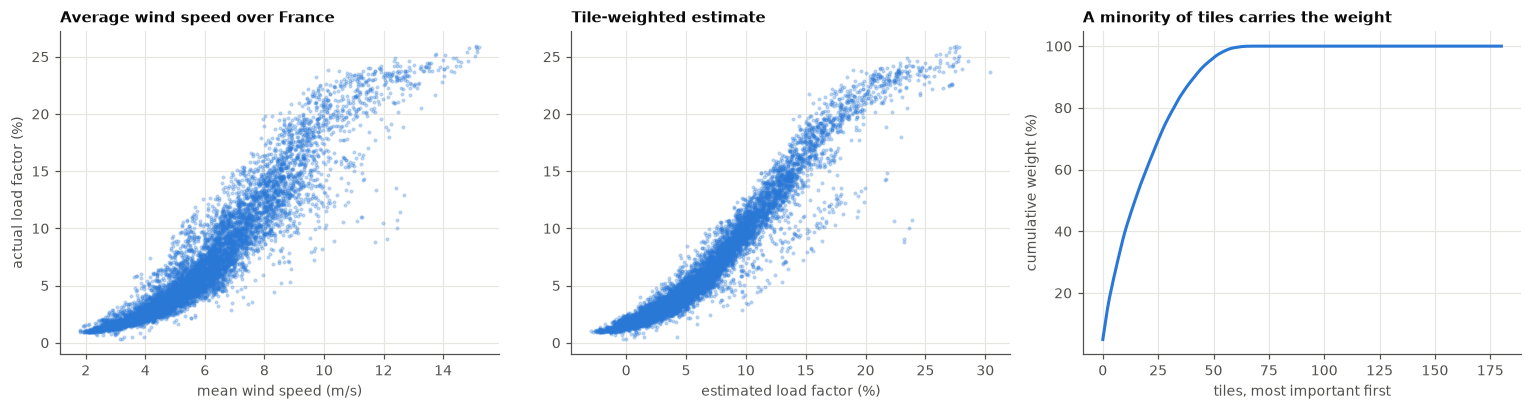

In [13]:
share_wind = targets.FR_wind_actual / network.FR_capacity_wind
tiles = weather.xs("100ws", level="weather_var", axis=1)

rows = train & share_wind.notna().to_numpy()
tile_fit = LinearRegression(positive=True).fit(tiles[rows], share_wind[rows])
weighted = pd.Series(tile_fit.predict(tiles), index=tiles.index)

cols = [c for c in FEATURES["FR_wind_actual"] if c != "tiles"]
wind_no_tiles = (
    fct_notebook__fit_predict(X[train], share_wind[train], X[valid], cols) 
    * network.FR_capacity_wind[valid]
).clip(lower=0)

worth["Wind: learn which tiles matter"] = (
    fct_notebook__mae(wind_no_tiles, "FR_wind_actual"), 
    fct_notebook__mae(p24.FR_wind_actual, "FR_wind_actual")
)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
actual_pct = share_wind[valid] * 100
axes[0].scatter(X.ws_mean[valid], actual_pct, s=3, alpha=0.25, color=BLUE)
axes[0].set(title="Average wind speed over France", xlabel="mean wind speed (m/s)", ylabel="actual load factor (%)")
axes[1].scatter(weighted[valid] * 100, actual_pct, s=3, alpha=0.25, color=BLUE)
axes[1].set(title="Tile-weighted estimate", xlabel="estimated load factor (%)")
weights = np.sort(tile_fit.coef_)[::-1]
axes[2].plot(np.cumsum(weights) / weights.sum() * 100, color=BLUE)
axes[2].set(title="A minority of tiles carries the weight", xlabel="tiles, most important first", ylabel="cumulative weight (%)")
fig.tight_layout();

Left: the same average wind speed can mean very different output. Middle: much tighter, because the regression gives more weight to the tiles that matter. Right: a minority of tiles carries most of the weight.

> **Takeaway.** No map needed: a small positive regression finds where the production is.

### 4.3 Demand: a drop in late 2022 that never came back

I trained a demand model on weather and calendar only, up to summer 2022, and asked it to forecast everything after. Here is the gap between actual demand and that model, month by month:

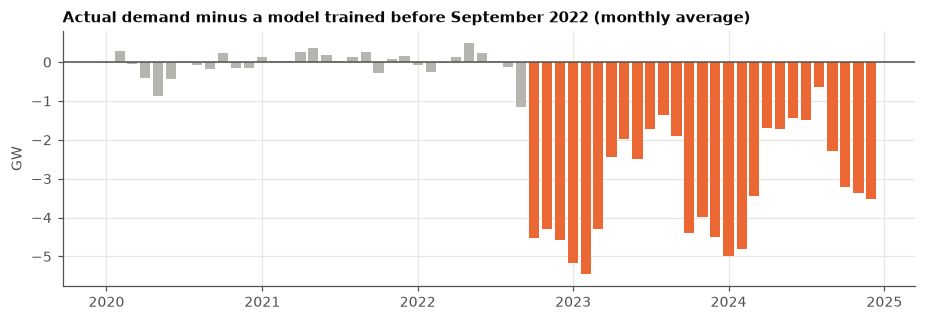

In [14]:
before = targets.index < pd.Timestamp("2022-09-01", tz="UTC")
cols = [c for c in FEATURES["FR_load_actual"] if c != "post_crisis"]
load_wx = fct_notebook__fit_predict(X[before], targets.FR_load_actual[before], X, cols)    # weather and calendar only
gap = ((targets.FR_load_actual - load_wx) / 1000).resample("MS").mean()
gap.index = gap.index.tz_localize(None)

no_flag = fct_notebook__fit_predict(X[train], targets.FR_load_actual[train], X[valid], cols)
worth["Demand: flag the post-2022 level"] = (fct_notebook__mae(no_flag, "FR_load_actual"), fct_notebook__mae(p24.FR_load_actual, "FR_load_actual"))

start = pd.Timestamp("2022-10-01")
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(gap.index, gap, width=24, color=[ORANGE if d >= start else MUTED for d in gap.index])
ax.axhline(0, color=GREY, lw=1)
ax.set(title="Actual demand minus a model trained before September 2022 (monthly average)", ylabel="GW");

From October 2022, demand sits *below* the forecast and stays there. It looks like a lasting effect of the energy crisis, but the data cannot say why, and no weather variable can see it. So the model gets a simple **flag**: "after October 2022". **It is a bet that 2025 looks like 2023 and 2024.**

### 4.4 Price: fuel sets the level

Electricity prices follow fuel prices. Top: the fuel prices in the data. Bottom: the power price next to **what the three fuel prices alone say about it**, from a simple regression of the price on gas, carbon and coal. No plant efficiency or emission factor is set by hand. (For this picture it is fitted on all five years; the model itself only uses the years before the one it forecasts.)

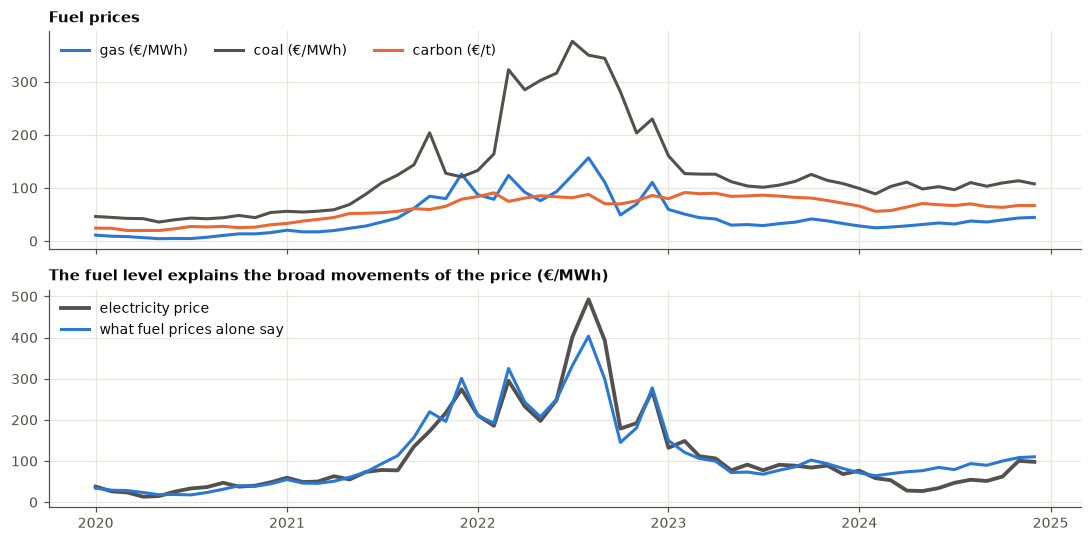

In [15]:
fuel_model = fct_models__fuel_model(network, targets.FR_price_actual)
fuel_cost = pd.Series(fuel_model.predict(network[FUELS]), index=network.index)   # what fuel prices alone say about the price

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
fuels_monthly = network[FUELS].resample("MS").mean()
for col, label, color in [("EEX_GAS_PEG", "gas (€/MWh)", BLUE), ("EEX_COAL", "coal (€/MWh)", GREY), ("EEX_CARBON", "carbon (€/t)", ORANGE)]:
    axes[0].plot(fuels_monthly.index, fuels_monthly[col], color=color, label=label)
axes[0].set(title="Fuel prices")
axes[0].legend(loc="upper left", ncol=3)

monthly_price = targets.FR_price_actual.resample("MS").mean()
axes[1].plot(monthly_price.index, monthly_price, color=GREY, lw=2.5, label="electricity price")
axes[1].plot(monthly_price.index, fuel_cost.resample("MS").mean(), color=BLUE, label="what fuel prices alone say")
axes[1].set(title="The fuel level explains the broad movements of the price (€/MWh)")
axes[1].legend(loc="upper left")
axes[1].xaxis.set_major_locator(mdates.YearLocator(1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout();

What is left, the gap between the price and the fuel level, is where the supply and demand of the hour come in. Next, the price against the **residual load**, one line per year. On the left the years are far apart; on the right, once the fuel level is removed, they line up:

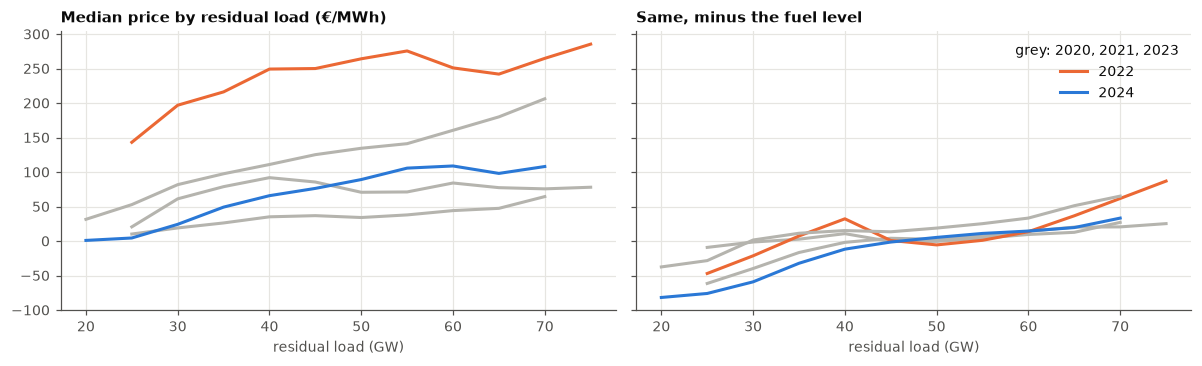

In [16]:
market = fct_features__market(network, targets.FR_load_actual, targets.FR_solar_actual, targets.FR_wind_actual)
df = pd.DataFrame({"price": targets.FR_price_actual, "gap": targets.FR_price_actual - fuel_cost,
                   "bin": (market.residual_load // 5000) * 5, "year": year})
groups = df.groupby(["year", "bin"])
median = groups[["price", "gap"]].median()[groups.size() >= 50]       # skip sparse bins

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for y in [2020, 2021, 2022, 2023, 2024]:
    color = {2022: ORANGE, 2024: BLUE}.get(y, MUTED)
    for ax, col in zip(axes, ["price", "gap"]):
        ax.plot(median.loc[y][col], color=color, label=y if y in (2022, 2024) else None)
axes[0].set(title="Median price by residual load (€/MWh)", xlabel="residual load (GW)")
axes[1].set(title="Same, minus the fuel level", xlabel="residual load (GW)")
axes[1].legend(title="grey: 2020, 2021, 2023")
fig.tight_layout();

So **the price model does not forecast the price, it forecasts the gap to the fuel level** from demand, solar, wind and available plants, and the fuel level is added back. Without this, it would learn the price level of whichever year it was trained on.

Note the left end of the 2024 line: at low residual load the price falls much lower than before. Those are the negative prices (section 7).

*(skip on first read)* A helper that rebuilds the price model's inputs for a validation year (actual demand, solar and wind for the training years, our forecasts for the year tested), then the comparison with learning the raw price.

In [17]:
def fct_notebook__price_inputs(vy):
    # features of the price model: actual demand/solar/wind for training years, our forecasts for the validation year
    tr, va, pred = year < vy, year == vy, results[vy]["pred"]
    Xtr = X[tr].join(fct_features__market(network[tr], targets.FR_load_actual[tr], targets.FR_solar_actual[tr], targets.FR_wind_actual[tr]))
    Xva = X[va].join(fct_features__market(network[va], pred.FR_load_actual, pred.FR_solar_actual, pred.FR_wind_actual))
    fuel = fct_models__fuel_model(network[tr], targets.FR_price_actual[tr])
    Xtr["fuel_cost"], Xva["fuel_cost"] = fuel.predict(network[tr][FUELS]), fuel.predict(network[va][FUELS])
    return Xtr, Xva


Xtr23, Xva23 = fct_notebook__price_inputs(2023)
raw_price_23 = fct_notebook__fit_predict(Xtr23, targets.FR_price_actual[year < 2023], Xva23, PF, objective="l1")
worth["Price: forecast the gap to the fuel level"] = (fct_notebook__mae(raw_price_23, "FR_price_actual"),
                                                      fct_notebook__mae(results[2023]["pred"].FR_price_actual, "FR_price_actual"))

> **Takeaway.** Separate what is explained by fuel prices from what is explained by the market of the hour. The first moved massively over the years, the second much less.

### The recap: what each idea was worth

                                           without     with   gain
Solar: forecast a share of capacity         805.49   393.92  51.10
Solar: learn which tiles matter             393.92   364.75   7.41
Wind: learn which tiles matter              933.60   560.59  39.95
Demand: flag the post-2022 level           1890.08  1074.26  43.16
Price: forecast the gap to the fuel level    20.35    17.78  12.63


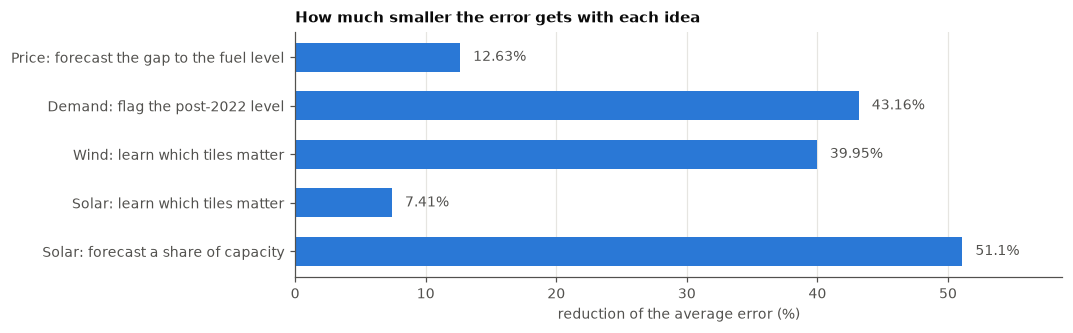

In [18]:
recap = round(pd.DataFrame(worth, index=["without", "with"]).T,2)
recap["gain"] = round((1 - recap["with"] / recap["without"]) * 100,2)   
#recap = recap.sort_values("gain")
print(recap)

fig, ax = plt.subplots(figsize=(9, 2.9))
ax.barh(recap.index, recap.gain, color=BLUE, height=0.6)
for i, g in enumerate(recap.gain):
    ax.text(g + 1, i, f"{g}%", va="center", color=GREY, fontsize=9)
ax.set(xlim=(0, max(recap.gain) * 1.15), title="How much smaller the error gets with each idea", xlabel="reduction of the average error (%)")
ax.grid(axis="y", visible=False);

Solar and demand gain the most. The tile weights matter a lot for wind, little for solar. For the price, the gain is more modest (measured on 2023).

## 5. Does it work?

*How good is the model, on years it has never seen?*

For each series, the average error as a share of its typical level, for the model and for the baseline (same hour, one year earlier).

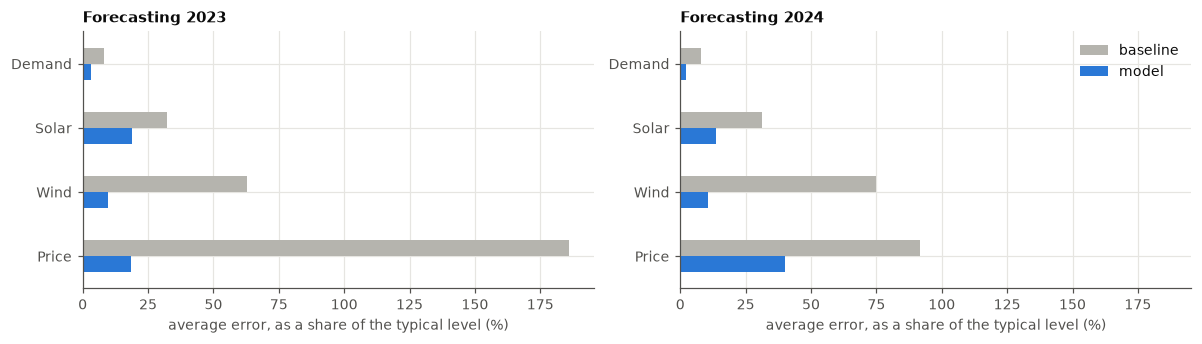

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, y in zip(axes, [2023, 2024]):
    r = results[y]
    errors = pd.DataFrame({
        "baseline": fct_notebook__level_error(r["truth"], fct_evaluate__seasonal_naive(targets, r["truth"].index)),
        "model": fct_notebook__level_error(r["truth"], r["pred"]),
    }).loc[ORDER].rename(index=NAMES)
    errors.plot.barh(ax=ax, color=[MUTED, BLUE], legend=(y == 2024))
    ax.invert_yaxis()
    ax.set(title=f"Forecasting {y}", xlabel="average error, as a share of the typical level (%)")
fig.tight_layout();

The model beats the baseline on all four series, in both years. Demand and wind are close; **the price is by far the hardest**. (In 2023 the baseline for the price is the 2022 crisis year, so 2024 is the fairer comparison.)

What the errors look like, on two weeks of 2024:

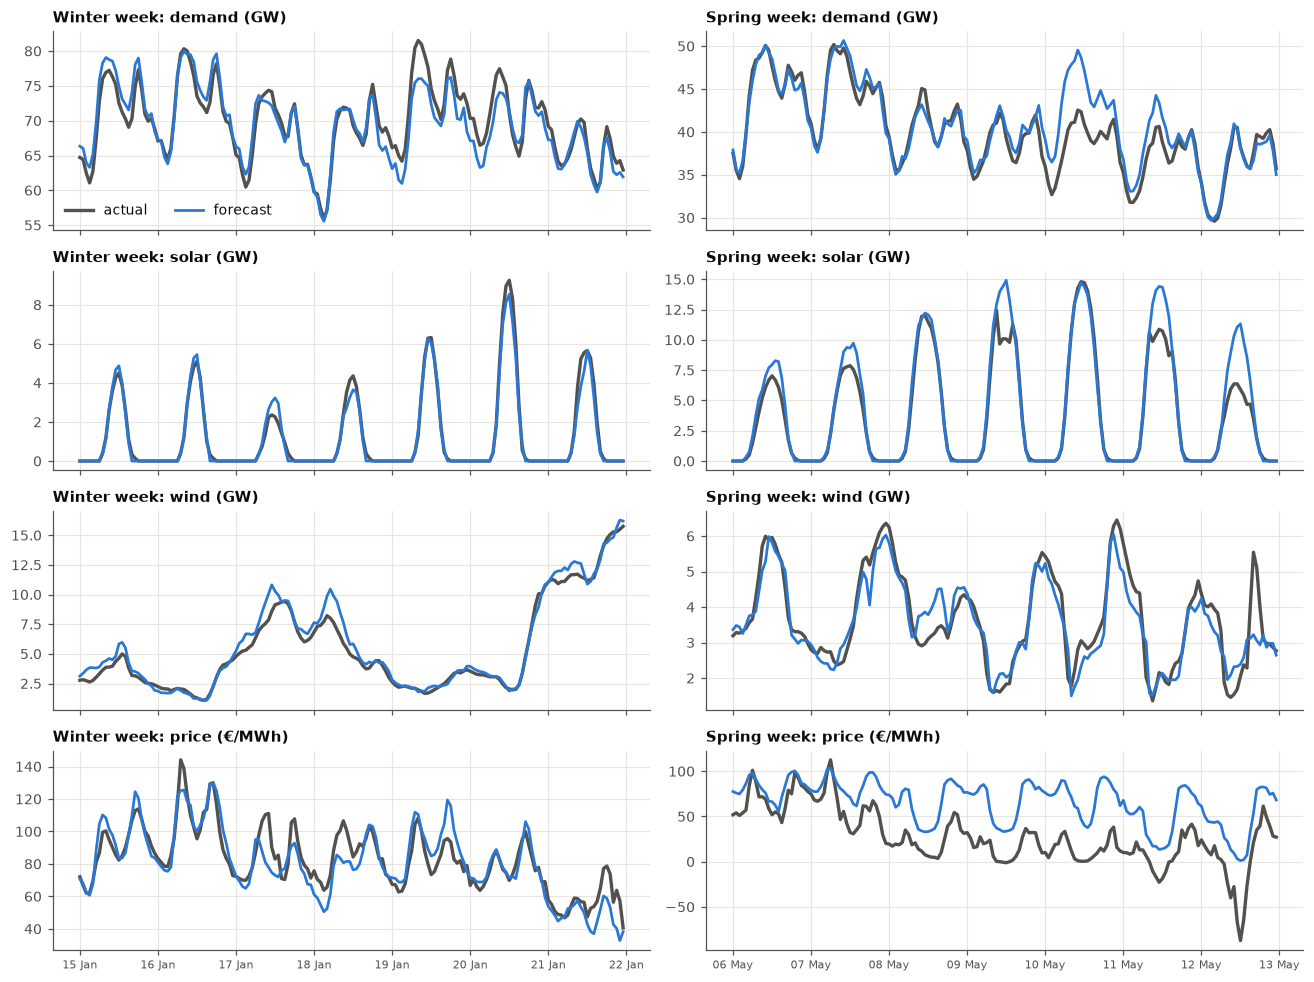

In [20]:
weeks = [("Winter week", slice("2024-01-15", "2024-01-21")), ("Spring week", slice("2024-05-06", "2024-05-12"))]
fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex="col")
for j, (label, wk) in enumerate(weeks):
    for i, col in enumerate(ORDER):
        scale = 1 if col == "FR_price_actual" else 1 / 1000
        fct_notebook__week(axes[i, j], t24[col][wk] * scale, p24[col][wk] * scale,
                           f"{label}: {NAMES[col].lower()} ({'€/MWh' if col == 'FR_price_actual' else 'GW'})")
axes[0, 0].legend(loc="lower left", ncol=2)
fig.tight_layout();

In winter the forecast follows the actual series closely, price included. In spring the price forecast sits above the actual most of the time and misses the deepest dips. Section 7 is about exactly that.

> **Takeaway.** Demand and wind are well under control, solar by day, but **the price is still an issue during Spring**.

## 6. Opening the price model

*How does the model arrive at a price?*

The price is the hardest series, so it deserves an explanation. **SHAP** splits each forecast into contributions: how much each input pushed *this hour's* price up or down, compared with an average hour. They add up exactly to the forecast.

Two details. The **fuel level is the starting point** of each explanation, since the model forecasts the gap to it. And several inputs say almost the same thing (demand, residual load...), so I **grouped them** by theme, otherwise SHAP splits the credit arbitrarily.

In [21]:
Xtr24, Xva24 = fct_notebook__price_inputs(2024) # the inputs the 2024 price model actually received
price_model = results[2024]["model"].models["FR_price_actual"]
explainer = shap.TreeExplainer(price_model)
shap_values = pd.DataFrame(explainer.shap_values(Xva24[PF]), index=Xva24.index, columns=PF)
typical_gap = float(np.ravel(explainer.expected_value)[0]) # the average gap to the fuel level

GROUPS = {"Calendar": CALENDAR,
          "Demand and renewables": ["load", "residual_load", "residual_after_nuclear", "renewable_share"],
          "Fuel prices": ["EEX_GAS_PEG", "EEX_CARBON", "EEX_COAL", "fuel_cost"],
          "Plants available": [c for c in PF if c.startswith("FR_availability")]}
by_group = pd.DataFrame({name: shap_values[cols].sum(axis=1) for name, cols in GROUPS.items()})

check = Xva24.fuel_cost + typical_gap + by_group.sum(axis=1) - p24.FR_price_actual
print("largest gap between 'fuel level + contributions' and the forecast, in €/MWh:", round(check.abs().max(), 4))

largest gap between 'fuel level + contributions' and the forecast, in €/MWh: 0.0002


**What matters most?** The average size of each group's contribution over 2024. Fuel looks small because the fuel level is already the starting point:

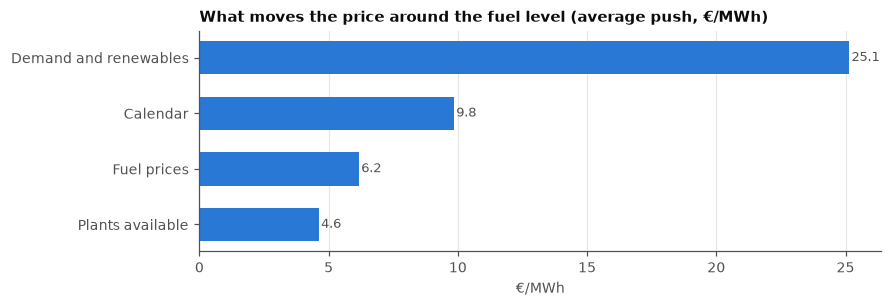

In [22]:
importance = by_group.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(importance.index, importance, color=BLUE, height=0.6)
for i, v in enumerate(importance):
    ax.text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=8.5, color=GREY)
ax.set(title="What moves the price around the fuel level (average push, €/MWh)", xlabel="€/MWh")
ax.grid(axis="y", visible=False);

**Two hours, explained.** Left: a winter weekday evening, one of the most expensive hours of 2024. Right: the cheapest hour. The bars add up to the forecast; the *typical gap* is how far an average hour sits from the fuel level.

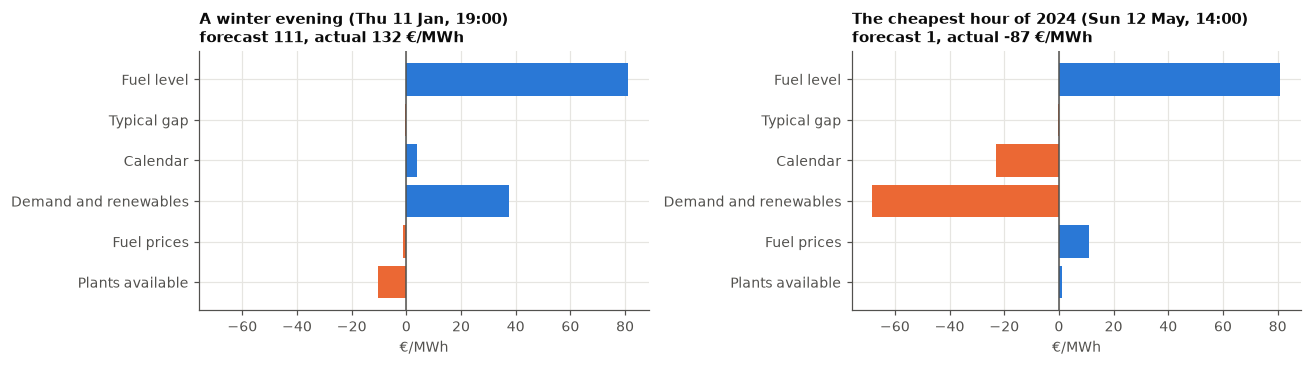

In [23]:
local = Xva24.index.tz_convert("Europe/Paris")
evenings = Xva24.index[(local.month == 1) & (local.hour == 19) & (local.day_of_week < 5)]
hours = {"A winter evening": t24.FR_price_actual[evenings].idxmax(), "The cheapest hour of 2024": t24.FR_price_actual.idxmin()}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
for ax, (label, h) in zip(axes, hours.items()):
    steps = pd.Series({"Fuel level": Xva24.fuel_cost[h], "Typical gap": typical_gap, **by_group.loc[h].to_dict()})
    ax.barh(steps.index, steps, color=[BLUE if v >= 0 else ORANGE for v in steps])
    ax.invert_yaxis()
    ax.axvline(0, color=GREY, lw=1)
    ax.set(title=f"{label} ({h.tz_convert('Europe/Paris'):%a %d %b, %H:%M})\nforecast {p24.FR_price_actual[h]:.0f}, actual {t24.FR_price_actual[h]:.0f} €/MWh", xlabel="€/MWh")
fig.tight_layout();

On the evening, fuel sets a high base and the demand that solar and wind do not cover pushes it further up. For the cheapest hour, the model *does* see the cause (lots of solar, low demand) but not far enough: the forecast stays well above the actual price, which went deeply negative.

**The core mechanism.** How the forecast reacts to residual load alone. Each dot is one hour of 2024:

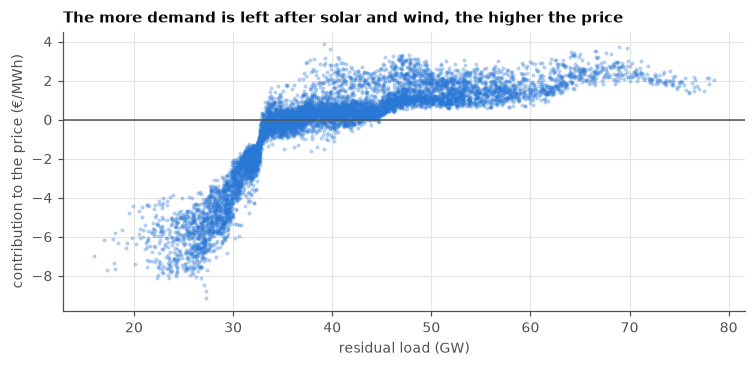

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.scatter(Xva24.residual_load / 1000, shap_values.residual_load, s=3, alpha=0.25, color=BLUE)
ax.axhline(0, color=GREY, lw=1)
ax.set(title="The more demand is left after solar and wind, the higher the price", xlabel="residual load (GW)", ylabel="contribution to the price (€/MWh)");

When little demand is left (lots of solar and wind), the price is pushed down hard, and that is where the negative prices live. Beyond a point the effect flattens.

> **Takeaway.** The model learned the mechanism one would hope for: fuel sets the level, and the demand that solar and wind do not cover moves the price around it. What it cannot know is what the data does not contain, and that is where it fails next.

## 7. Where it still fails

*What does it get wrong, and why?*

Average error per month on 2024 (above zero means the forecast is too high):

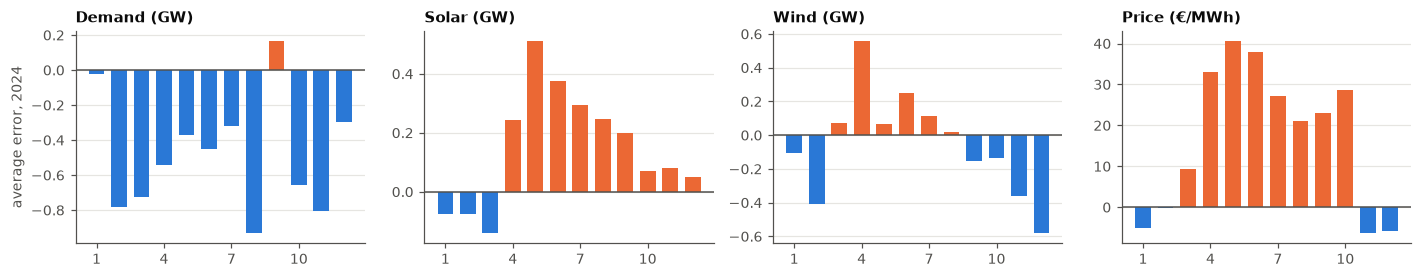

In [25]:
bias = (p24 - t24).groupby(p24.index.month).mean()
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, col in zip(axes, ORDER):
    scale = 1 if col == "FR_price_actual" else 1 / 1000
    b = bias[col] * scale
    ax.bar(b.index, b, color=[ORANGE if v > 0 else BLUE for v in b], width=0.7)
    ax.axhline(0, color=GREY, lw=1)
    ax.set(title=f"{NAMES[col]} ({'€/MWh' if col == 'FR_price_actual' else 'GW'})", xticks=[1, 4, 7, 10])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("average error, 2024")
fig.tight_layout();

Demand is a little low most of the year, solar too high in summer, and the price too high from spring to autumn. The last two are the most instructive.

**The price.** From 2020 to 2023 the price stayed close to the fuel level. In 2024 it fell far below it for months, and negative prices became much more common. A model that never saw such a market overshoots.

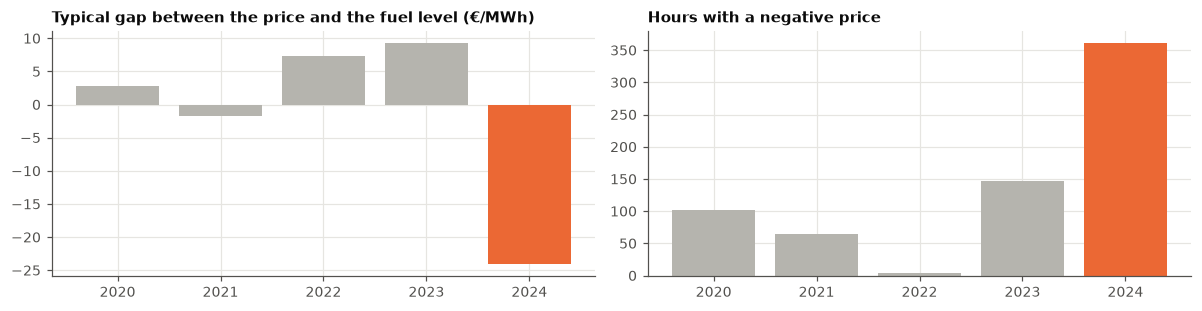

In [26]:
gap_by_year = (targets.FR_price_actual - fuel_cost).groupby(year).median()
negative_hours = (targets.FR_price_actual < 0).groupby(year).sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 2.9))
for ax, s, title in [(axes[0], gap_by_year, "Typical gap between the price and the fuel level (€/MWh)"),
                     (axes[1], negative_hours, "Hours with a negative price")]:
    ax.bar(s.index, s, color=[ORANGE if y == 2024 else MUTED for y in s.index])
    ax.set_title(title)
fig.tight_layout();

The data does not say why. Cross-border exchanges, the water stored behind hydro dams or the way operators bid could all play a role, but none of it is in the files. Retraining differently would not fix a missing explanation.

> **Takeaway.** The price error comes from a market the data cannot describe.

## 8. The 2025 forecast

*Does the forecast behave sensibly?*

There are no real 2025 values, so I cannot show how accurate the forecast is: the honest estimate of its errors is the 2024 validation above. What I can check is that the forecast moves the way its inputs moved (more sun and more panels, so more solar). A forecast moving against its drivers would point to a bug.

The final model is trained on 2020 to 2024 and reloaded here:

In [29]:
model = Forecaster.load(ROOT / "models")
pred25 = model.predict(weather_25, network_25)
submitted = pd.read_parquet(ROOT / "test_results.parquet").set_index("start_date")
assert (pred25 - submitted).abs().max().max() < 1e-6          # the saved file is exactly this forecast
print(f"{len(pred25)} hourly forecasts for 2025, no missing value: {pred25.notna().all().all()}")

8760 hourly forecasts for 2025, no missing value: True


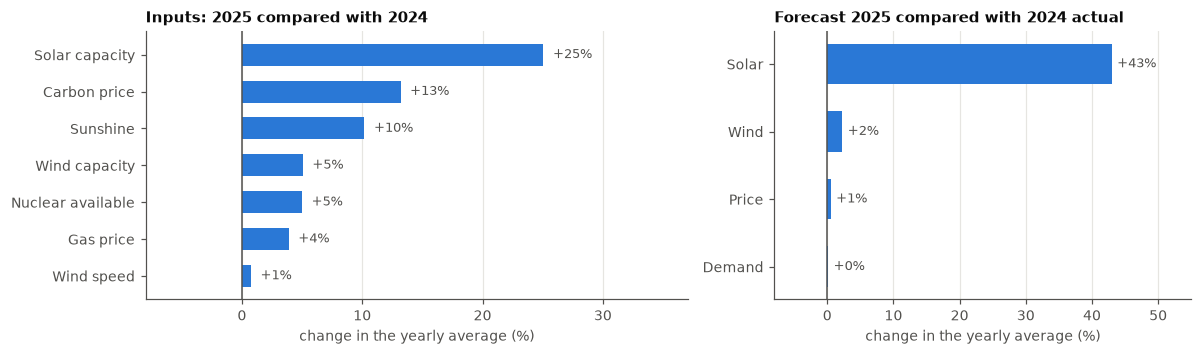

In [30]:
y24 = year == 2024
w24, w25 = fct_features__weather(weather)[y24], fct_features__weather(weather_25)
drivers = {"Solar capacity": (network.FR_capacity_solar[y24], network_25.FR_capacity_solar), "Sunshine": (w24.ssrd_mean, w25.ssrd_mean),
           "Wind capacity": (network.FR_capacity_wind[y24], network_25.FR_capacity_wind), "Wind speed": (w24.ws_mean, w25.ws_mean),
           "Gas price": (network.EEX_GAS_PEG[y24], network_25.EEX_GAS_PEG), "Carbon price": (network.EEX_CARBON[y24], network_25.EEX_CARBON),
           "Nuclear available": (network.FR_availability_nuclear[y24], network_25.FR_availability_nuclear)}
inputs_change = pd.Series({k: (b.mean() / a.mean() - 1) * 100 for k, (a, b) in drivers.items()}).sort_values()
outputs_change = pd.Series({NAMES[c]: (pred25[c].mean() / targets[c][y24].mean() - 1) * 100 for c in ORDER}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1.3, 1]})
for ax, s, title in [(axes[0], inputs_change, "Inputs: 2025 compared with 2024"), (axes[1], outputs_change, "Forecast 2025 compared with 2024 actual")]:
    ax.barh(s.index, s, color=BLUE, height=0.6)
    for i, v in enumerate(s):
        ax.text(v + (0.8 if v >= 0 else -0.8), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=GREY)
    ax.axvline(0, color=GREY, lw=1)
    ax.set(title=title, xlabel="change in the yearly average (%)", xlim=(min(s.min() - 8, -8), s.max() + 12))
    ax.grid(axis="y", visible=False)
fig.tight_layout();

In [31]:
summer = lambda s: s[s.index.month.isin([5, 6, 7, 8])].mean()
share_of_capacity = lambda output, cap: summer(output / cap) * 100
seen = ", ".join(f"{y}: {share_of_capacity(targets.FR_solar_actual[year == y], network.FR_capacity_solar[year == y]):.0f}%" for y in [2022, 2023, 2024])
print(f"Solar, average share of capacity produced from May to August. Actual: {seen}. "
      f"Forecast 2025: {share_of_capacity(pred25.FR_solar_actual, network_25.FR_capacity_solar):.0f}%")

Solar, average share of capacity produced from May to August. Actual: 2022: 22%, 2023: 20%, 2024: 17%. Forecast 2025: 20%


Everything moves with its drivers. Solar is up the most, because the fleet is bigger and the year sunnier; demand stays put, as the post-2022 flag intends; wind and the average price barely move. The solar jump is large, so I checked it (printout above): the share of capacity produced in summer is close to what earlier sunny years saw. The forecast also ignores curtailment, so I expect it to be too high on sunny weekends.

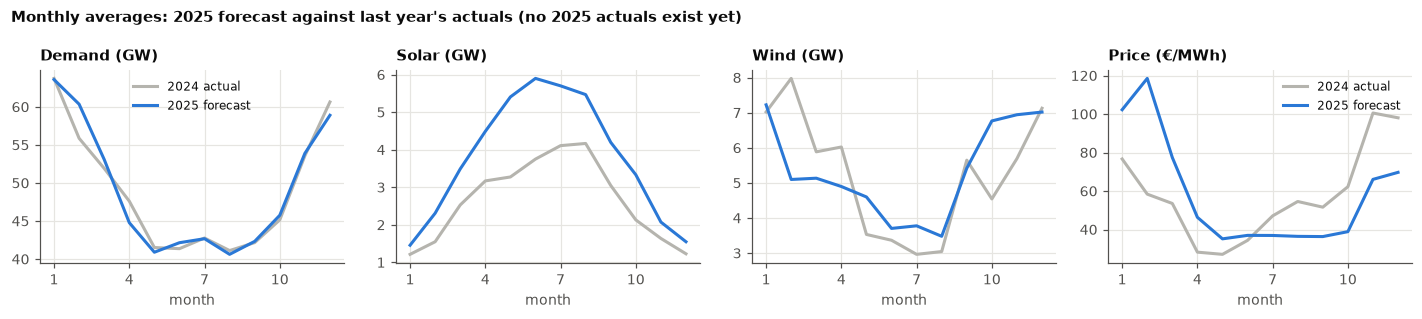

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, col in zip(axes, ORDER):
    scale = 1 if col == "FR_price_actual" else 1 / 1000
    last = targets[col][y24].groupby(targets.index[y24].month).mean() * scale
    forecast = pred25[col].groupby(pred25.index.month).mean() * scale
    ax.plot(last, color=MUTED, label="2024 actual")
    ax.plot(forecast, color=BLUE, label="2025 forecast")
    ax.set(title=f"{NAMES[col]} ({'€/MWh' if col == 'FR_price_actual' else 'GW'})", xticks=[1, 4, 7, 10], xlabel="month")
axes[0].legend(loc="upper center", fontsize=8)
axes[3].legend(loc="upper right", fontsize=8)
fig.suptitle("Monthly averages: 2025 forecast against last year's actuals (no 2025 actuals exist yet)", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout();

> **Takeaway.** The forecast is coherent with its inputs. Its weak spots are known: solar on sunny weekends, negative prices, and the level of the price in spring and summer, where the 2024 validation ran high.

## 9. Next steps

*What would I do with more time, or more data?*

First caveat: **the 2025 weather here is what really happened, not a weather forecast.** A real day-ahead system would use weather forecasts and do worse, especially for wind.

With more time, in order of expected value:

1. **A solar model that knows about the price**, or a correction driven by the price forecast (section 7). It is the clearest error I found, and it will grow with the fleet.
2. **Train the price model on forecasts** of demand, solar and wind instead of actuals, so it learns from inputs that look like what it receives in practice. Not tested here.
3. **Flag negative-price hours** with a classifier ("price below zero?"), used as a ranking of the riskiest hours rather than as an alarm. Not tested here.
4. **Watch the monthly error in production.** The 2022 drop in demand and the 2024 price show that the market can change faster than a yearly retraining.

With more data: **cross-border electricity exchanges, hydro reservoir levels**, and a clarification of the wind capacity column. I expect them to explain most of what the price did in 2024.

### Reproduce it

```bash
pip install -r requirements.txt && pip install -e .
python -m kpler_forecast.cli all      # validations, final training, test_results.parquet (about 30 seconds)
jupyter notebook notebooks/case_study_v4.ipynb
```

The Kpler data files go in **data/**. Models are saved under **models/<version>/** with their settings and scores, and **predict --split 2026** forecasts any later year with the same input files.